# 8. Tutorial 8

**Course:** High Switching Frequency Power Converters

## 8.1 Charge and energy of the ZVS transition

Half-bridge at $V_\mathrm{DC} = 48~\mathrm{V}$, output capacitance of each transistor $C_\mathrm{oss}(v) = C_0/\sqrt{1+v/V_\mathrm{j}}$ with $C_0 = 443~\mathrm{pF}$ and $V_\mathrm{j} = 5~\mathrm{V}$. During the dead time the inductor $L$ (other end at $V_x$) drives the current $i$ into the switch node:
$$\frac{\mathrm{d}v}{\mathrm{d}t} = \frac{i}{C_\mathrm{oss}(v) + C_\mathrm{oss}(V_\mathrm{DC}-v)}, \qquad \frac{\mathrm{d}i}{\mathrm{d}t} = \frac{V_x - v}{L}.$$

8.1.1 Import necessary modules (numpy as np, matplotlib.pyplot as plt, scipy.integrate, scipy.optimize) and create the functions
- `get_Coss(v)`, `get_Qoss(V)` and `get_Eoss(V)` (numerical integration with `quad`).

Print $Q_\mathrm{oss}$, $E_\mathrm{oss}$, $C_\mathrm{o(tr)}$ and $C_\mathrm{o(er)}$ at $48~\mathrm{V}$.

8.1.2 Create the function `simulate_transition(I0, L, Vx)` that integrates the two equations from $v = 0$, $i = I_0$ until the node reaches $V_\mathrm{DC}$ (or for $60~\mathrm{ns}$). Plot $v$ and $i$ for $I_0 = 3$ and $1.5~\mathrm{A}$ with $L = 200~\mathrm{nH}$ and $V_x = 0$. Print the transition time and the final current and compare them with $2Q_\mathrm{oss}/I_0$ and $\sqrt{I_0^2 - 2Q_\mathrm{oss}(V_\mathrm{DC}-2V_x)/L}$.

8.1.3 Find the minimum initial current for complete ZVS by bisection for $L = 200~\mathrm{nH}$, $V_x = 0$ and for $L = 225~\mathrm{nH}$, $V_x = 12~\mathrm{V}$, and compare it with $\sqrt{2Q_\mathrm{oss}(V_\mathrm{DC}-2V_x)/L}$.


In [1]:
# Subtask 8.1.1 Import necessary modules and create the functions
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq

V_DC, C0, Vj = 48.0, 443e-12, 5.0


def get_Coss(v):
    """Output capacitance of one transistor in F at the drain-source voltage v (v < 0 treated as 0)."""
    return C0 / np.sqrt(1 + np.maximum(v, 0) / Vj)


def get_Qoss(V):
    """Output charge in C, integral of Coss from 0 to V."""
    return quad(get_Coss, 0, max(V, 0))[0]


def get_Eoss(V):
    """Stored energy in J, integral of v Coss from 0 to V."""
    return quad(lambda v: v * get_Coss(v), 0, max(V, 0))[0]


Q48, E48 = get_Qoss(V_DC), get_Eoss(V_DC)
print(f"Qoss(48 V) = {Q48*1e9:.2f} nC, Eoss(48 V) = {E48*1e6:.3f} uJ")
print(f"Co(tr) = {Q48/V_DC*1e12:.0f} pF, Co(er) = {2*E48/V_DC**2*1e12:.0f} pF, Coss(48 V) = {get_Coss(V_DC)*1e12:.0f} pF")


Qoss(48 V) = 9.99 nC, Eoss(48 V) = 0.197 uJ
Co(tr) = 208 pF, Co(er) = 171 pF, Coss(48 V) = 136 pF


I0 = 3.0 A: ZVS after 7.45 ns (stiff current: 6.66 ns), final current 2.050 A (energy balance: 2.050 A)


I0 = 1.5 A: no ZVS, the node stops at 34.4 V after 14.2 ns


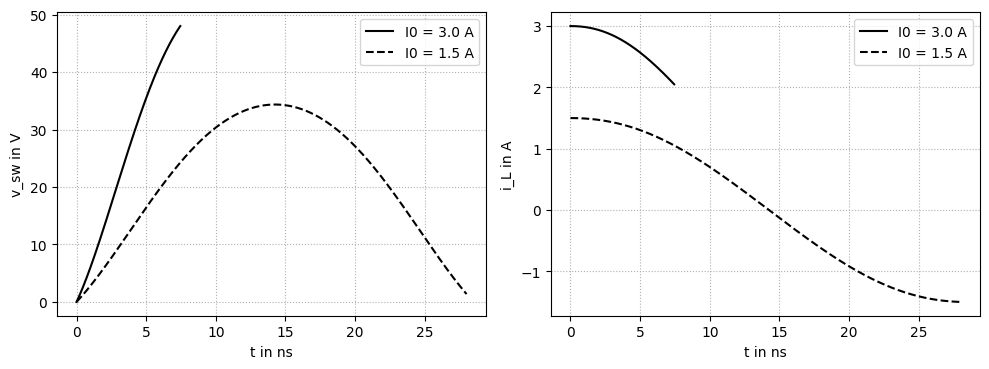

In [2]:
# Subtask 8.1.2 Transition of the switch node
def simulate_transition(I0, L, Vx, V=V_DC, t_max=60e-9):
    """Switch node from 0 towards V with the inductor current I0 flowing into the node.
    Returns the solution of solve_ivp; integration stops when the node reaches V."""
    def rhs(t, y):
        v, i = y
        return [i / (get_Coss(v) + get_Coss(V - v)), (Vx - v) / L]
    reach = lambda t, y: y[0] - V
    reach.terminal, reach.direction = True, 1
    return solve_ivp(rhs, [0, t_max], [0.0, I0], events=reach, max_step=0.02e-9, rtol=1e-9, atol=1e-13)


fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for I0, ls in ((3.0, '-'), (1.5, '--')):
    s = simulate_transition(I0, 200e-9, 0.0, t_max=28e-9)
    ax[0].plot(s.t * 1e9, s.y[0], 'k' + ls, label=f'I0 = {I0} A')
    ax[1].plot(s.t * 1e9, s.y[1], 'k' + ls, label=f'I0 = {I0} A')
    if s.t_events[0].size:
        W = Q48 * (V_DC - 0.0)
        print(f"I0 = {I0} A: ZVS after {s.t_events[0][0]*1e9:.2f} ns (stiff current: {2*Q48/I0*1e9:.2f} ns), "
              f"final current {s.y[1][-1]:.3f} A (energy balance: {np.sqrt(I0**2 - 2*W/200e-9):.3f} A)")
    else:
        k = np.argmax(s.y[0])
        print(f"I0 = {I0} A: no ZVS, the node stops at {s.y[0][k]:.1f} V after {s.t[k]*1e9:.1f} ns")
ax[0].set_ylabel('v_sw in V'); ax[1].set_ylabel('i_L in A')
for a in ax:
    a.set_xlabel('t in ns'); a.grid(True, ls=':'); a.legend()
plt.tight_layout(); plt.show()


In [3]:
# Subtask 8.1.3 Minimum current for complete ZVS
def get_I_min(L, Vx):
    """Smallest initial current for which the node reaches V_DC (bisection)."""
    f = lambda I0: simulate_transition(I0, L, Vx).y[0].max() - (V_DC - 1e-3)
    return brentq(f, 0.2, 10.0, xtol=1e-4)


for L, Vx in ((200e-9, 0.0), (225e-9, 12.0)):
    print(f"L = {L*1e9:.0f} nH, Vx = {Vx:4.1f} V: I_min = {get_I_min(L, Vx):.3f} A (energy formula: "
          f"{np.sqrt(2*Q48*(V_DC - 2*Vx)/L):.3f} A)")


L = 200 nH, Vx =  0.0 V: I_min = 2.190 A (energy formula: 2.190 A)


L = 225 nH, Vx = 12.0 V: I_min = 1.460 A (energy formula: 1.460 A)


### 8.1.3 Solution

$Q_\mathrm{oss} = 10.0~\mathrm{nC}$, $E_\mathrm{oss} = 0.197~\mu\mathrm{J}$, $C_\mathrm{o(tr)} = 208~\mathrm{pF}$, $C_\mathrm{o(er)} = 171~\mathrm{pF}$; the small-signal value at $48~\mathrm{V}$ is only $136~\mathrm{pF}$. With $3~\mathrm{A}$ the node reaches $48~\mathrm{V}$ after $7.45~\mathrm{ns}$ (stiff current: $6.66~\mathrm{ns}$) and the current falls to $2.05~\mathrm{A}$, exactly as the energy balance predicts. With $1.5~\mathrm{A}$ the node stops at $34.4~\mathrm{V}$ after $14.2~\mathrm{ns}$ and swings back. The bisection gives $2.19~\mathrm{A}$ and $1.46~\mathrm{A}$, equal to $\sqrt{2Q_\mathrm{oss}(V_\mathrm{DC}-2V_x)/L}$: the energy needed depends on $Q_\mathrm{oss}$ only, not on the shape of $C_\mathrm{oss}(v)$.


## 8.2 Buck converter in triangular current mode

$V_\mathrm{in} = 48~\mathrm{V}$, $V_\mathrm{o} = 12~\mathrm{V}$, $P_\mathrm{o} = 100~\mathrm{W}$, $L = 225~\mathrm{nH}$, $R_\mathrm{DS(on)} = 7~\mathrm{m\Omega}$, $I_\mathrm{neg} = 1.67~\mathrm{A}$, transistors of 8.1.

8.2.1 Create the function `get_tcm(load, I_neg, f_max)` that returns $f_\mathrm{sw}$, $I_\mathrm{neg}$, the peak current and the rms current; with a frequency limit $f_\mathrm{max}$ the negative current grows instead. Plot $f_\mathrm{sw}$ and $I_\mathrm{rms}$ versus the load ($5 \ldots 100~\%$) without limit and with $f_\mathrm{max} = 4~\mathrm{MHz}$.

8.2.2 Extend the model of 8.1.2 by the reverse conduction of both transistors when the node leaves the rails (about $1.5~\mathrm{V} + 0.1~\Omega \cdot i$) and simulate the high-side transition with $I_0 = I_\mathrm{neg}$ and $V_x = V_\mathrm{o}$ for $60~\mathrm{ns}$. If the high side turns on at $t_\mathrm{d}$ with the node at $v$, the bus charges the low-side capacitance from $v$ to $V$ through the channel, and the high-side capacitance discharges into its own channel:
$$E_\mathrm{on}(v) = V\left[Q(V) - Q(v)\right] - \left[E(V) - E(v)\right] + E(V - v).$$
Add the reverse-conduction loss up to $t_\mathrm{d}$, plot the turn-on loss versus $t_\mathrm{d}$ and find the dead-time window in which it stays below $5~\%$ of $Q_\mathrm{oss}V$.


load 100 %: f_sw = 2.00 MHz, peak 18.33 A, rms 10.14 A, conduction loss   719 mW
load  50 %: f_sw = 3.43 MHz, peak 10.00 A, rms  5.36 A, conduction loss   201 mW
load  10 %: f_sw = 8.00 MHz, peak  3.33 A, rms  1.67 A, conduction loss    19 mW
10 % load, f limited to 4 MHz: I_neg = 4.17 A, rms 3.00 A, conduction loss 63 mW


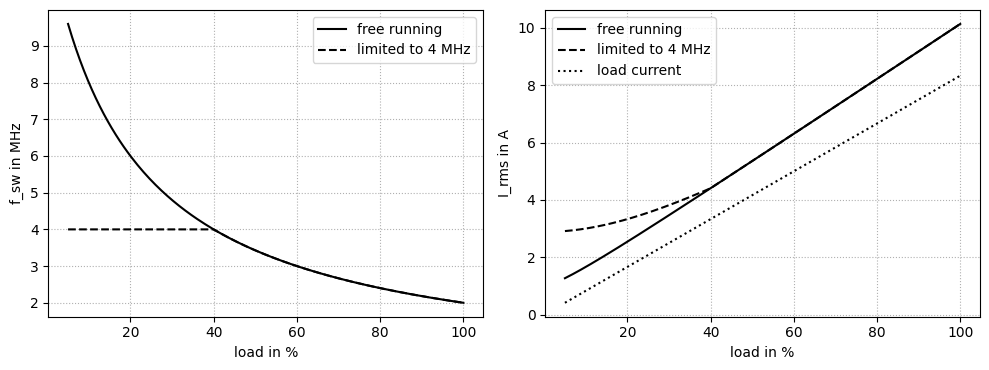

In [4]:
# Subtask 8.2.1 TCM operating points over the load
V_in, V_o, P_o, L_tcm, R_on, I_neg = 48.0, 12.0, 100.0, 225e-9, 7e-3, 1.667


def get_tcm(load, I_neg=I_neg, f_max=None):
    """f_sw, I_neg, peak and rms inductor current of the TCM buck at the relative load."""
    I_o = P_o / V_o * load
    f = V_o * (1 - V_o / V_in) / (2 * L_tcm * (I_o + I_neg))
    if f_max is not None and f > f_max:
        f = f_max
        I_neg = V_o * (1 - V_o / V_in) / (2 * L_tcm * f) - I_o
    di = 2 * (I_o + I_neg)
    return f, I_neg, 2 * I_o + I_neg, np.sqrt(I_o**2 + di**2 / 12)


for load in (1.0, 0.5, 0.1):
    f, In, Ipk, Irms = get_tcm(load)
    print(f"load {load*100:3.0f} %: f_sw = {f/1e6:.2f} MHz, peak {Ipk:5.2f} A, rms {Irms:5.2f} A, "
          f"conduction loss {Irms**2*R_on*1e3:5.0f} mW")
f, In, Ipk, Irms = get_tcm(0.1, f_max=4e6)
print(f"10 % load, f limited to 4 MHz: I_neg = {In:.2f} A, rms {Irms:.2f} A, conduction loss {Irms**2*R_on*1e3:.0f} mW")

loads = np.linspace(0.05, 1, 200)
res = np.array([get_tcm(x) for x in loads]); res_c = np.array([get_tcm(x, f_max=4e6) for x in loads])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(loads * 100, res[:, 0] / 1e6, 'k-', label='free running')
ax[0].plot(loads * 100, res_c[:, 0] / 1e6, 'k--', label='limited to 4 MHz')
ax[1].plot(loads * 100, res[:, 3], 'k-', label='free running')
ax[1].plot(loads * 100, res_c[:, 3], 'k--', label='limited to 4 MHz')
ax[1].plot(loads * 100, P_o / V_o * loads, 'k:', label='load current')
ax[0].set_ylabel('f_sw in MHz'); ax[1].set_ylabel('I_rms in A')
for a in ax:
    a.set_xlabel('load in %'); a.grid(True, ls=':'); a.legend()
plt.tight_layout(); plt.show()


transition with I_neg = 1.667 A: 13.4 ns (stiff current 12.0 ns), current max 1.76 A, at the end 0.80 A
current reverses after 18.2 ns
turn-on loss below 5 % of 480 nJ for t_d = 9.1 ... 26.5 ns


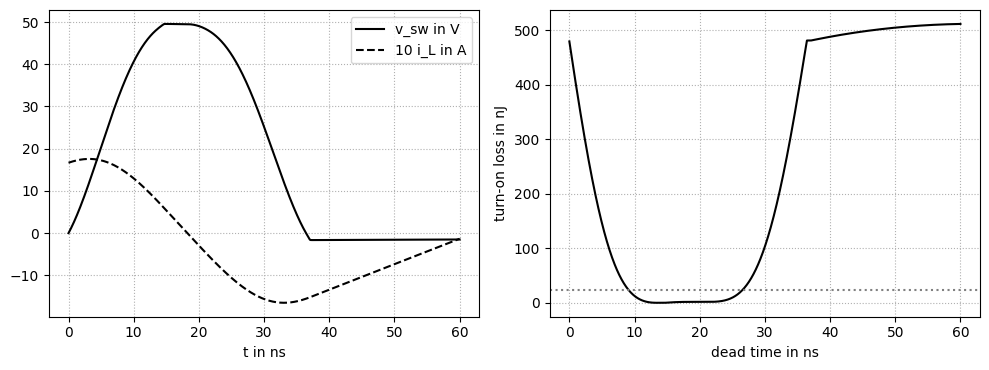

In [5]:
# Subtask 8.2.2 High-side transition with I_neg and turn-on loss versus dead time
V_on, R_rev = 1.5, 0.1   # reverse conduction of a GaN transistor with v_GS = 0 (about 2 V at 5 A)


def get_Qoss_a(v):
    """Analytical Qoss of the model (faster than quad inside loops)."""
    v = np.clip(v, 0, None)
    return 2 * C0 * Vj * (np.sqrt(1 + v / Vj) - 1)


def get_Eoss_a(v):
    """Analytical Eoss of the model."""
    u = 1 + np.clip(v, 0, None) / Vj
    return C0 * Vj**2 * (2 / 3 * (u**1.5 - 1) - 2 * (u**0.5 - 1))


def simulate_dead_time(I0, L, Vx, V=V_DC, t_max=60e-9):
    """Node, current and reverse-conduction energy during a dead time of length t_max (dense output)."""
    def rhs(t, y):
        v, i, e = y
        i_hs = max(0.0, (v - V - V_on) / R_rev)    # high side conducts in reverse (node above the bus)
        i_ls = max(0.0, (-v - V_on) / R_rev)       # low side conducts in reverse (node below ground)
        C_t = get_Coss(min(max(V - v, 0), V)) + get_Coss(min(max(v, 0), V))
        return [(i - i_hs + i_ls) / C_t, (Vx - v) / L, i_hs * (v - V) + i_ls * (-v)]
    return solve_ivp(rhs, [0, t_max], [0.0, I0, 0.0], method='LSODA', max_step=0.02e-9,
                     rtol=1e-8, atol=[1e-6, 1e-9, 1e-15], dense_output=True)


def get_E_on(v, V=V_DC):
    """Capacitive loss when the high side turns on with the node at v."""
    v = min(max(v, 0), V)
    return V * (get_Qoss_a(V) - get_Qoss_a(v)) - (get_Eoss_a(V) - get_Eoss_a(v)) + get_Eoss_a(V - v)


s = simulate_dead_time(I_neg, L_tcm, V_o)
t_zvs = simulate_transition(I_neg, L_tcm, V_o).t_events[0][0]
td = np.linspace(0, 60e-9, 1201)
v, i, e = s.sol(td)
E_on = np.array([get_E_on(x) for x in v]) + e
E_hard = get_Qoss_a(V_DC) * V_DC
window = td[E_on < 0.05 * E_hard]
print(f"transition with I_neg = {I_neg} A: {t_zvs*1e9:.1f} ns (stiff current {2*Q48/I_neg*1e9:.1f} ns), "
      f"current max {i[td <= t_zvs].max():.2f} A, at the end {np.interp(t_zvs, td, i):.2f} A")
print(f"current reverses after {td[np.argmax((i < 0) & (td > t_zvs))]*1e9:.1f} ns")
print(f"turn-on loss below 5 % of {E_hard*1e9:.0f} nJ for t_d = {window.min()*1e9:.1f} ... {window.max()*1e9:.1f} ns")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(td * 1e9, v, 'k-', label='v_sw in V')
ax[0].plot(td * 1e9, 10 * i, 'k--', label='10 i_L in A')
ax[0].set_xlabel('t in ns'); ax[0].grid(True, ls=':'); ax[0].legend()
ax[1].plot(td * 1e9, E_on * 1e9, 'k-')
ax[1].axhline(0.05 * E_hard * 1e9, color='gray', ls=':')
ax[1].set_xlabel('dead time in ns'); ax[1].set_ylabel('turn-on loss in nJ'); ax[1].grid(True, ls=':')
plt.tight_layout(); plt.show()


### 8.2.2 Solution

The frequency rises from $2~\mathrm{MHz}$ at full load to $8~\mathrm{MHz}$ at $10~\%$ load; the rms current stays above $I_\mathrm{neg}/\sqrt{3} = 0.96~\mathrm{A}$ even without load, and at $10~\%$ load it is twice the load current. With the $4~\mathrm{MHz}$ limit the negative current rises to $4.17~\mathrm{A}$ at $10~\%$ load and the rms current to $3.0~\mathrm{A}$ (conduction loss $63~\mathrm{mW}$ instead of $19~\mathrm{mW}$), in exchange for half the frequency-proportional losses.

The high-side transition with $I_\mathrm{neg} = 1.67~\mathrm{A}$ takes $13.4~\mathrm{ns}$ instead of the $12.0~\mathrm{ns}$ of a stiff current: below $12~\mathrm{V}$ the current still rises (to $1.76~\mathrm{A}$), above it falls to $0.80~\mathrm{A}$. The turn-on loss is below $5~\%$ of the hard-switched $0.48~\mu\mathrm{J}$ for dead times of about $9$ to $26~\mathrm{ns}$. A dead time that is a few ns too short costs little (partial ZVS); one that is much too long lets the current reverse (after about $18~\mathrm{ns}$) and the node swing back, and after about $35~\mathrm{ns}$ the turn-on is practically hard again.


## 8.3 Dual active bridge

$V_1 = 48~\mathrm{V}$, $V_2 = 10 \ldots 14~\mathrm{V}$, $n = 4$, $f_\mathrm{sw} = 1~\mathrm{MHz}$, $L = 0.8~\mu\mathrm{H}$, $Q_\mathrm{oss} = 10~\mathrm{nC}$ (primary) and $20~\mathrm{nC}$ (secondary), rated power $200~\mathrm{W}$.

8.3.1 Create the functions `get_phi(V2, P)` and `get_dab(V2, phi)`; the latter returns $P$, $i(0)$, $i(\varphi)$ and the rms value of the inductor current (numerically over a half period). Print the operating points at $200~\mathrm{W}$ for $V_2 = 10$, $12$ and $14~\mathrm{V}$.

8.3.2 Compute the minimum power for ZVS of both bridges over $V_2 = 10 \ldots 14~\mathrm{V}$ with the current-sign criterion and with the charge criterion ($|i(0)| \geq 2Q_\mathrm{oss,p}/t_\mathrm{d}$, $n\,i(\varphi) \geq 2Q_\mathrm{oss,s}/t_\mathrm{d}$) for $t_\mathrm{d} = 5$ and $10~\mathrm{ns}$. Plot the boundaries together with the rated power.


In [6]:
# Subtask 8.3.1 DAB operating points
V1, n_dab, f_dab, L_dab, P_rated = 48.0, 4, 1e6, 0.8e-6, 200.0
Q_p, Q_s = 10e-9, 20e-9


def get_phi(V2, P):
    """Phase shift in rad (smaller root) for the power P."""
    a = 2 * np.pi**2 * f_dab * L_dab * P / (n_dab * V1 * V2)
    return (np.pi - np.sqrt(np.pi**2 - 4 * a)) / 2


def get_dab(V2, phi, N=4001):
    """Power, i(0), i(phi) and rms inductor current (primary side) for single phase shift."""
    d = n_dab * V2 / V1
    I1 = V1 / (4 * f_dab * L_dab)
    i0 = -I1 * (1 - d + 2 * d * phi / np.pi)
    ip = I1 * (d - 1 + 2 * phi / np.pi)
    P = n_dab * V1 * V2 * phi * (np.pi - phi) / (2 * np.pi**2 * f_dab * L_dab)
    th = np.linspace(0, np.pi, N)
    wL = 2 * np.pi * f_dab * L_dab
    i = np.where(th < phi, i0 + (V1 + n_dab * V2) / wL * th, ip + (V1 - n_dab * V2) / wL * (th - phi))
    return P, i0, ip, np.sqrt(np.trapezoid(i**2, th) / np.pi)


for V2 in (10.0, 12.0, 14.0):
    phi = get_phi(V2, P_rated)
    P, i0, ip, irms = get_dab(V2, phi)
    print(f"V2 = {V2:4.1f} V: phi = {np.degrees(phi):5.2f} deg, i(0) = {i0:6.2f} A, i(phi) = {ip:5.2f} A "
          f"(secondary {n_dab*ip:5.2f} A), rms {irms:.2f} A")


V2 = 10.0 V: phi = 38.04 deg, i(0) =  -7.78 A, i(phi) =  3.84 A (secondary 15.36 A), rms 5.56 A
V2 = 12.0 V: phi = 30.00 deg, i(0) =  -5.00 A, i(phi) =  5.00 A (secondary 20.00 A), rms 4.71 A
V2 = 14.0 V: phi = 24.86 deg, i(0) =  -2.33 A, i(phi) =  6.64 A (secondary 26.58 A), rms 4.50 A


current sign: 92 W at 10 V, 0 W at 12 V, 111 W at 14 V
charge, t_d = 5 ns: 153 W at 10 V, 166 W at 12 V, 254 W at 14 V


charge, t_d = 10 ns: 124 W at 10 V, 90 W at 12 V, 188 W at 14 V


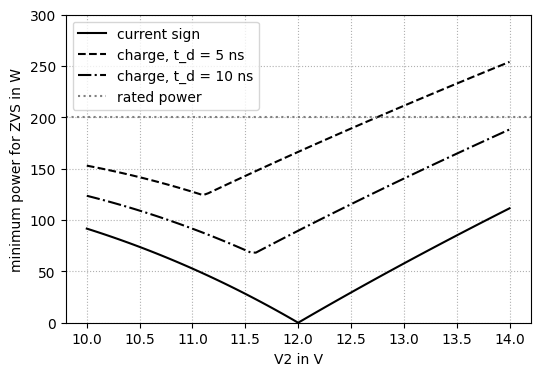

In [7]:
# Subtask 8.3.2 ZVS boundaries: current sign and charge criterion
def get_margin(V2, phi, t_d=None):
    """Smaller of the two ZVS margins in A (primary -i(0), secondary n i(phi)); both grow with phi."""
    P, i0, ip, _ = get_dab(V2, phi, N=3)
    req_p, req_s = (0.0, 0.0) if t_d is None else (2 * Q_p / t_d, 2 * Q_s / t_d)
    return min(-i0 - req_p, n_dab * ip - req_s)


def get_P_min(V2, t_d=None):
    """Smallest power with ZVS of both bridges (current sign if t_d is None)."""
    lo, hi = 1e-9, np.pi / 2
    if get_margin(V2, lo, t_d) >= 0:
        return 0.0
    if get_margin(V2, hi, t_d) < 0:
        return np.nan
    phi = brentq(lambda x: get_margin(V2, x, t_d), lo, hi, xtol=1e-10)
    return get_dab(V2, phi, N=3)[0]


V2s = np.linspace(10, 14, 81)
cases = ((None, 'k-', 'current sign'), (5e-9, 'k--', 'charge, t_d = 5 ns'), (10e-9, 'k-.', 'charge, t_d = 10 ns'))
plt.figure(figsize=(6, 4))
for t_d, ls, lab in cases:
    Pm = np.array([get_P_min(x, t_d) for x in V2s])
    plt.plot(V2s, Pm, ls, label=lab)
    print(lab + ": " + ", ".join(f"{get_P_min(x, t_d):.0f} W at {x:.0f} V" for x in (10, 12, 14)))
plt.axhline(P_rated, color='gray', ls=':', label='rated power')
plt.xlabel('V2 in V'); plt.ylabel('minimum power for ZVS in W'); plt.ylim(0, 300)
plt.grid(True, ls=':'); plt.legend(); plt.show()


### 8.3.2 Solution

At $200~\mathrm{W}$: $\varphi = 38.0^\circ$, $30.0^\circ$ and $24.9^\circ$; $i(0) = -7.78$, $-5.00$ and $-2.33~\mathrm{A}$; $i(\varphi) = 3.84$, $5.00$ and $6.64~\mathrm{A}$; rms current $5.56$, $4.71$ and $4.50~\mathrm{A}$ at $10$, $12$ and $14~\mathrm{V}$.

The current sign gives ZVS above $92~\mathrm{W}$ at $10~\mathrm{V}$ (secondary), at every load at $12~\mathrm{V}$ and above $111~\mathrm{W}$ at $14~\mathrm{V}$ (primary). The charge criterion is much stricter: with $5~\mathrm{ns}$ dead time $153$, $166$ and $254~\mathrm{W}$, with $10~\mathrm{ns}$ $124$, $90$ and $188~\mathrm{W}$. With $d = 1$ the bridges switch with small currents at light load, so even there the transition does not complete within the dead time. A DAB designed with the current sign alone is partly hard-switched in practice; extended modulation, a variable frequency or an adaptive dead time are needed (Lecture 8).


## 8.4 Lagging leg of a phase-shifted full bridge

$V_\mathrm{in} = 400~\mathrm{V}$, $V_\mathrm{o} = 48~\mathrm{V}$, $P_\mathrm{o} = 1~\mathrm{kW}$, $n = 6$, $C_\mathrm{oss}(v) = 50~\mathrm{pF} + 434~\mathrm{pF}\cdot e^{-v/83~\mathrm{V}}$.

8.4.1 Plot versus $L_\mathrm{lk} = 2 \ldots 30~\mu\mathrm{H}$ the minimum load for ZVS of the lagging leg ($\frac{1}{2}L_\mathrm{lk}I_\mathrm{p}^2 \geq Q_\mathrm{oss}V_\mathrm{in}$) and the duty-cycle loss $\Delta D = 4L_\mathrm{lk}I_\mathrm{p}f_\mathrm{sw}/V_\mathrm{in}$ at full load for $200~\mathrm{kHz}$, $500~\mathrm{kHz}$ and $1~\mathrm{MHz}$. Mark the largest duty-cycle loss that still allows $48~\mathrm{V}$ ($D \leq 1$).


Qoss(400 V) = 55.7 nC, I_p = 3.47 A, effective duty cycle 0.72
L_lk = 14.8 uH: ZVS down to 50 % load
f_sw =   200 kHz: duty-cycle loss limits L_lk to 40.32 uH, ZVS then down to 30 % load
f_sw =   500 kHz: duty-cycle loss limits L_lk to 16.13 uH, ZVS then down to 48 % load
f_sw =  1000 kHz: duty-cycle loss limits L_lk to  8.06 uH, ZVS then down to 68 % load


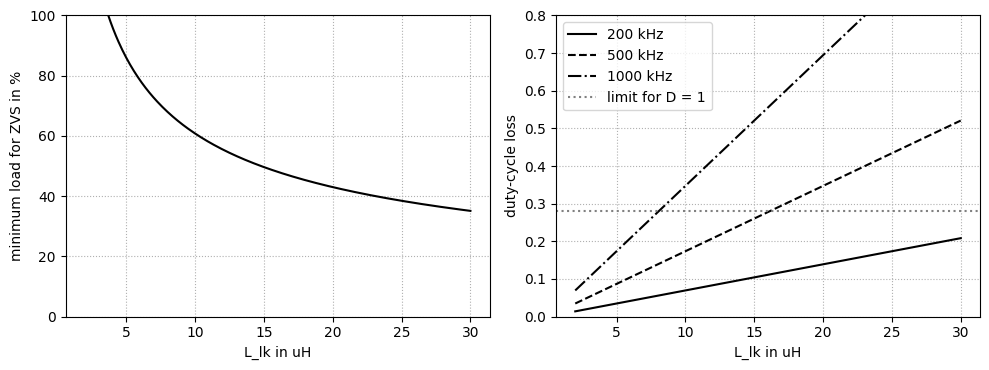

In [8]:
# Subtask 8.4.1 Leakage inductance of the PSFB: ZVS range versus duty-cycle loss
V_in4, V_o4, P_o4, n4 = 400.0, 48.0, 1000.0, 6
Q_400 = quad(lambda v: 50e-12 + 434e-12 * np.exp(-v / 83), 0, V_in4)[0]
I_p = P_o4 / V_o4 / n4
D_eff = n4 * V_o4 / V_in4
L_lk = np.linspace(2e-6, 30e-6, 300)
load_min = np.sqrt(2 * Q_400 * V_in4 / L_lk) / I_p
print(f"Qoss(400 V) = {Q_400*1e9:.1f} nC, I_p = {I_p:.2f} A, effective duty cycle {D_eff:.2f}")
print(f"L_lk = 14.8 uH: ZVS down to {np.sqrt(2*Q_400*V_in4/14.8e-6)/I_p*100:.0f} % load")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(L_lk * 1e6, load_min * 100, 'k-')
ax[0].set_ylabel('minimum load for ZVS in %'); ax[0].set_ylim(0, 100)
for f_sw, ls in ((200e3, '-'), (500e3, '--'), (1e6, '-.')):
    dD = 4 * L_lk * I_p * f_sw / V_in4
    ax[1].plot(L_lk * 1e6, dD, 'k' + ls, label=f'{f_sw/1e3:.0f} kHz')
    L_max = (1 - D_eff) * V_in4 / (4 * I_p * f_sw)
    print(f"f_sw = {f_sw/1e3:5.0f} kHz: duty-cycle loss limits L_lk to {L_max*1e6:5.2f} uH, "
          f"ZVS then down to {min(np.sqrt(2*Q_400*V_in4/L_max)/I_p, 9.99)*100:.0f} % load")
ax[1].axhline(1 - D_eff, color='gray', ls=':', label='limit for D = 1')
ax[1].set_ylabel('duty-cycle loss'); ax[1].set_ylim(0, 0.8); ax[1].legend()
for a in ax:
    a.set_xlabel('L_lk in uH'); a.grid(True, ls=':')
plt.tight_layout(); plt.show()


### 8.4.1 Solution

$Q_\mathrm{oss}(400~\mathrm{V}) = 55.7~\mathrm{nC}$, $I_\mathrm{p} = 3.47~\mathrm{A}$ at full load. With $L_\mathrm{lk} = 14.8~\mu\mathrm{H}$ the lagging leg keeps ZVS down to $50~\%$ load. A duty-cycle loss of at most $1 - D_\mathrm{eff} = 0.28$ limits $L_\mathrm{lk}$ to $40~\mu\mathrm{H}$ at $200~\mathrm{kHz}$ (ZVS down to $30~\%$ load), $16~\mu\mathrm{H}$ at $500~\mathrm{kHz}$ ($48~\%$) and $8~\mu\mathrm{H}$ at $1~\mathrm{MHz}$ ($68~\%$, with no margin left for the input-voltage range). The ZVS range of the PSFB shrinks with the frequency.
